In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

from time import time

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA 
from sklearn.preprocessing import scale


from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler,MinMaxScaler, MaxAbsScaler

from sklearn.utils import check_array, check_random_state
from sklearn.utils import shuffle as util_shuffle

import numpy as np
import warnings

from sklearn.base import BaseEstimator, ClusterMixin, TransformerMixin
from sklearn.metrics.pairwise import PAIRWISE_DISTANCE_FUNCTIONS
from sklearn.utils import check_array, check_random_state
from sklearn.utils.validation import check_is_fitted


import pyclust
import pandas

In [2]:

np.random.seed(0)

cs_arry=[[0,.75,0,1],[1,0,0,1],[0,0,1,1],[.9,.9,0,1],[1,0,1,1],[0,.9,.9,1]]# green red blue yellow purple cyan
cs_arry=np.array(cs_arry * 300)
colors = np.array([x for x in cs_arry]) # maybe not need this was colors = np.array([x for x in 'bgrcmykbgrcmykbgrcmykbgrcmyk'])

cs_arry4=[[0,.75,0,1],[1,0,0,1],[0,0,1,1],[1,1,0,1]]
cs_arry4=np.array(cs_arry4 * 300)
colors_4 = np.array([x for x in cs_arry4]) 

cs_arry3=[[0,.75,0,1],[1,0,0,1],[0,0,1,1]]
cs_arry3=np.array(cs_arry3 * 300)
colors_3 = np.array([x for x in cs_arry3])

#################
n_pts = 1500
std=1.25     
#################
#Noisy concentric circles
noisy_circles = datasets.make_circles(n_samples=n_pts, factor=.5, noise=.05)
##############################################
#Different density blobs
np.random.seed(0)
blobs1_1=datasets.make_blobs(n_samples=600, n_features=2, centers=[[-10, -10]], cluster_std=2.2, 
                          center_box=(-20,20), shuffle=True)
blobs2_1=datasets.make_blobs(n_samples=175, n_features=2, centers=[[10, 10]], cluster_std=2.55, 
                          center_box=(-20,20), shuffle=True)
blobs3_1=datasets.make_blobs(n_samples=35, n_features=2, centers=[[-4, 10]], cluster_std=3.25, 
                          center_box=(-20,20), shuffle=True) #centers=(-5, 5)
blobs_1_1=np.concatenate((blobs1_1[0],blobs2_1[0],blobs3_1[0]))
blobs_density=(blobs_1_1,None)


# def multiple_density_blobs(samples=[300,150,30], center=blob_centers, cluster_std=2):
# 	for x in len(samples):
##############################################
#Outlier blob
np.random.seed(0)
blobs1_2=datasets.make_blobs(n_samples=125, n_features=2, centers=[[-10, -10]], cluster_std=std, 
                          center_box=(-100,20), shuffle=True)
blobs2_2=datasets.make_blobs(n_samples=50, n_features=2, centers=[[10, -3]], cluster_std=std, 
                          center_box=(-20,20), shuffle=True)
# blobs3_2=datasets.make_blobs(n_samples=1, n_features=2, centers=(2, 10), cluster_std=std, 
#                           center_box=(-20,20), shuffle=True, random_state=0)
blobs3_2=[[-2,10]]
blobs_1_2=np.concatenate((blobs1_2[0],blobs2_2[0],blobs3_2))
blobs_out=blobs_1_2, None

##############################################
#4 Different clusters
np.random.seed(0)
#[(-10, -10), (-7, 10), (1, 10),(10, 3)] #1 
blobs=datasets.make_blobs(n_samples=600, n_features=2, centers=[[-10, -10], [-5, 10], [1, 10],[10, 3]], cluster_std=std, 
                          center_box=(-20,20), shuffle=True)

#############################################

In [ ]:
blobs

In [12]:
data_sets = [noisy_circles, blobs_density, blobs_out, blobs]
clustering_names=['Input','K-means','K-medoids','AP','Spectral','Gaussian','Hierarchical','DBSCAN']
#clustering_names=['Input','AP','Gaussian']
plt.figure(figsize=(len(clustering_names) * 2 + 3, 9.5))
plt.subplots_adjust(left=.02, right=.98, bottom=.001, top=.96, wspace=0,
                    hspace=0)
plot_num = 1


/Users/yeo2/anaconda/lib/python2.7/site-packages/sklearn/utils/deprecation.py:57: DeprecationWarning: Class GMM is deprecated; The class GMM is deprecated in 0.18 and will be  removed in 0.20. Use class GaussianMixture instead.
  warnings.warn(msg, category=DeprecationWarning)
/Users/yeo2/anaconda/lib/python2.7/site-packages/sklearn/utils/deprecation.py:75: DeprecationWarning: Function distribute_covar_matrix_to_match_covariance_type is deprecated; The function distribute_covar_matrix_to_match_covariance_typeis deprecated in 0.18 and will be removed in 0.20.
  warnings.warn(msg, category=DeprecationWarning)
/Users/yeo2/anaconda/lib/python2.7/site-packages/sklearn/utils/deprecation.py:75: DeprecationWarning: Function log_multivariate_normal_density is deprecated; The function log_multivariate_normal_density is deprecated in 0.18 and will be removed in 0.20.
  warnings.warn(msg, category=DeprecationWarning)
/Users/yeo2/anaconda/lib/python2.7/site-packages/sklearn/utils/deprecation.py:75:

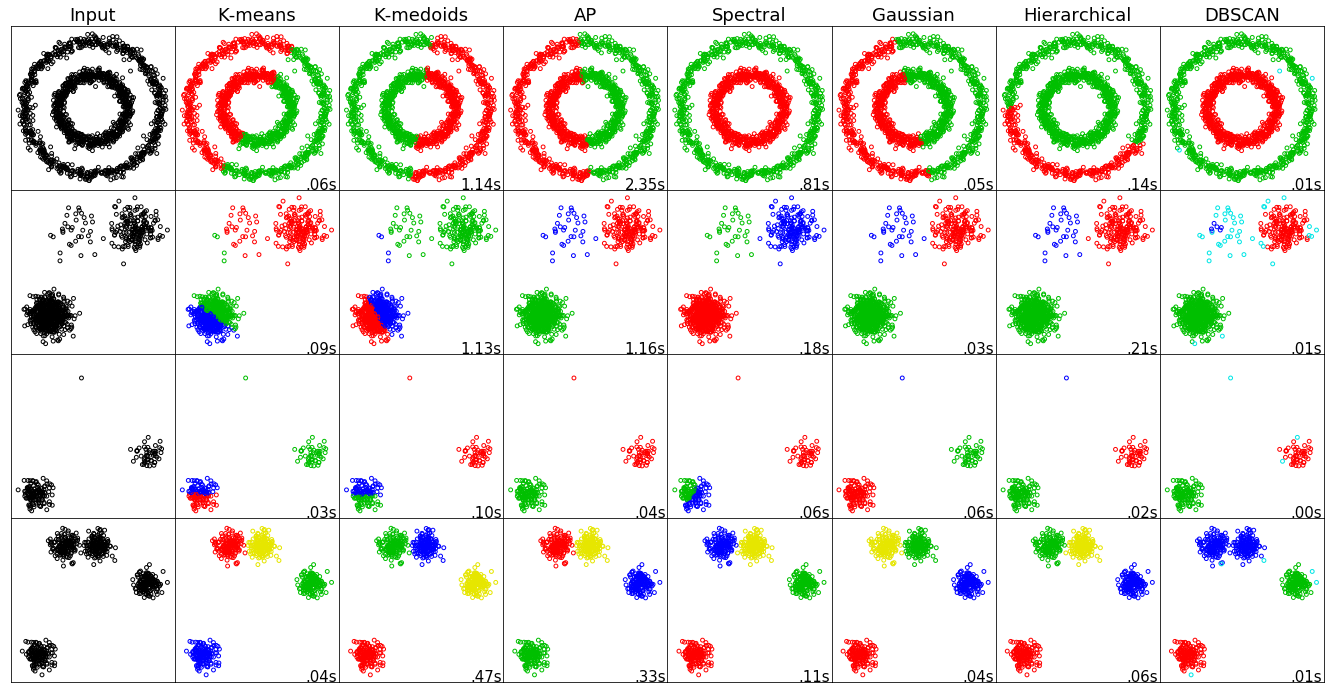

In [13]:
for i_dataset, dataset in enumerate(data_sets):
    no_cluster=[2,3,3,4]
    #ap_pref=[-300,-10,-1.5,-10] for #1 blobs 4 blob cluster more separated
    ap_pref=[-295,-10,-3,-1.5] # for #2 blobs cluster more closer 
#     sp_affinity=['nearest_neighbors','rbf','nearest_neighbors','rbf'] #nearest_neighbors
    sp_affinity=['rbf','rbf','rbf','rbf'] #nearest_neighbors
    x, y = dataset
    x =MaxAbsScaler().fit_transform(x)
    

    bandwidth = cluster.estimate_bandwidth(x, quantile=0.5)
    connectivity = kneighbors_graph(x, n_neighbors=10, include_self=True)#sy
    connectivity = 0.5 * (connectivity + connectivity.T)

#clustering algorithms
    orig_data=cluster.KMeans(n_clusters=1)
    
    #kmeans=cluster.KMeans(n_clusters=no_cluster[i_dataset],init='random',n_init=1,n_jobs=1, max_iter=50)
    kmeans=pyclust.KMeans(n_clusters=no_cluster[i_dataset])
    #kmedoids= KMedoids(n_clusters=no_cluster[i_dataset], max_iter=3000, random_state=None)
    kmedoids=pyclust.KMedoids(n_clusters=no_cluster[i_dataset], n_trials=5)
    
    heir = cluster.AgglomerativeClustering(n_clusters=no_cluster[i_dataset], linkage='ward',
                                           connectivity=connectivity)
    
    spectral = cluster.SpectralClustering(n_clusters=no_cluster[i_dataset],
                                              eigen_solver='arpack',
                                              affinity="nearest_neighbors")
#     spectral = cluster.SpectralClustering(n_clusters=no_cluster[i_dataset],
#                                           eigen_solver='arpack',
#                                           affinity='rbf')
#     spectral=cluster.SpectralClustering(n_clusters=no_cluster[i_dataset], eigen_solver=None, random_state=None, 
#                                         n_init=30, gamma=1.0, affinity=sp_affinity[i_dataset], n_neighbors=10, eigen_tol=0.0, 
#                                         assign_labels='kmeans', degree=3, coef0=1, kernel_params=None)
    
    ap = cluster.AffinityPropagation(damping=.9, preference=ap_pref[i_dataset], max_iter=750)

                                     
    gmm=mixture.GMM(n_components=no_cluster[i_dataset], covariance_type='spherical', tol=0.001, min_covar=0.000000001, n_iter=3000)
    
    dbscan=cluster.DBSCAN(eps=0.09, min_samples=6)

    #####################################
    #####################################
    
    clustering_algo=[orig_data, kmeans, kmedoids, ap, spectral, gmm, heir, dbscan]
    
    #####################################
    #####################################
    
    for name, algorithm in zip(clustering_names, clustering_algo):
        
        t0 = time()
        algorithm.fit(x)
        t1 = time()
        if hasattr(algorithm, 'labels_'):
            y_pred = algorithm.labels_.astype(np.int)
        else:
            y_pred = algorithm.predict(x)
        # save data 
        
        
        
        # plot
        plt.subplot(len(data_sets), len(clustering_algo), plot_num)

        if i_dataset == 0:
            plt.title(name, size=18)
#         if plot_num==10:
#             plt.scatter(x[:, 0], x[:, 1], color=colors[y_pred], s=15, marker='o', facecolors='none')
#         if plot_num==13:
#             plt.scatter(x[:, 0], x[:, 1], color=colors[y_pred], s=15, marker='o', facecolors='none')
        if name=='Input':
            plt.scatter(x[:, 0], x[:, 1], color='k', s=15, marker='o', facecolors='none')
        else: plt.scatter(x[:, 0], x[:, 1], color=colors[y_pred], s=15, marker='o', facecolors='none')

        plt.xlim(-1.1, 1.1)
        plt.ylim(-1.1, 1.1)
        plt.xticks(())
        plt.yticks(())
#         plt.text(.02, .01, ('%.2d' % plot_num),
#                      transform=plt.gca().transAxes, size=15,
#                      horizontalalignment='left')
    
        if name!='Input':
            plt.text(.99, .01, ('%.2fs' % (t1 - t0)).lstrip('0'),
                     transform=plt.gca().transAxes, size=15,
                     horizontalalignment='right')
            
        plot_num += 1

plt.show()

In [69]:
np.random.seed(0)
blobs1_1=datasets.make_blobs(n_samples=600, n_features=2, centers=[[-10, -10]], cluster_std=1.25, 
                          center_box=(-20,20), shuffle=True)
blobs2_1=datasets.make_blobs(n_samples=175, n_features=2, centers=[[10, 10]], cluster_std=1.25, 
                          center_box=(-20,20), shuffle=True)
blobs3_1=datasets.make_blobs(n_samples=35, n_features=2, centers=[[-4, 10]], cluster_std=1.25, 
                          center_box=(-20,20), shuffle=True) #centers=(-5, 5)
blobs_1_1=np.concatenate((blobs1_1[0],blobs2_1[0],blobs3_1[0]))
blobs_density=(blobs_1_1,None)
x, y=blobs_density

cs_arry=[[0,.75,0,1],[1,0,0,1],[0,0,1,1],[1,1,1,1],[1,1,1,1],[1,1,1,1]]# green red blue yellow purple cyan

colors = np.array([A for A in cs_arry]) # maybe not need this was 
colors = np.array([A for A in 'bgrkkk'])

In [70]:
# 
# spectral = cluster.SpectralClustering(n_clusters=3,
#                                           eigen_solver='arpack',
#                                           affinity="nearest_neighbors")

# spectral.fit(x)
# y_pred = spectral.labels_.astype(np.int)


In [71]:
# %matplotlib inline
# plt.scatter(x[:, 0], x[:, 1], color=colors[y_pred], s=15, marker='o', facecolors='none')

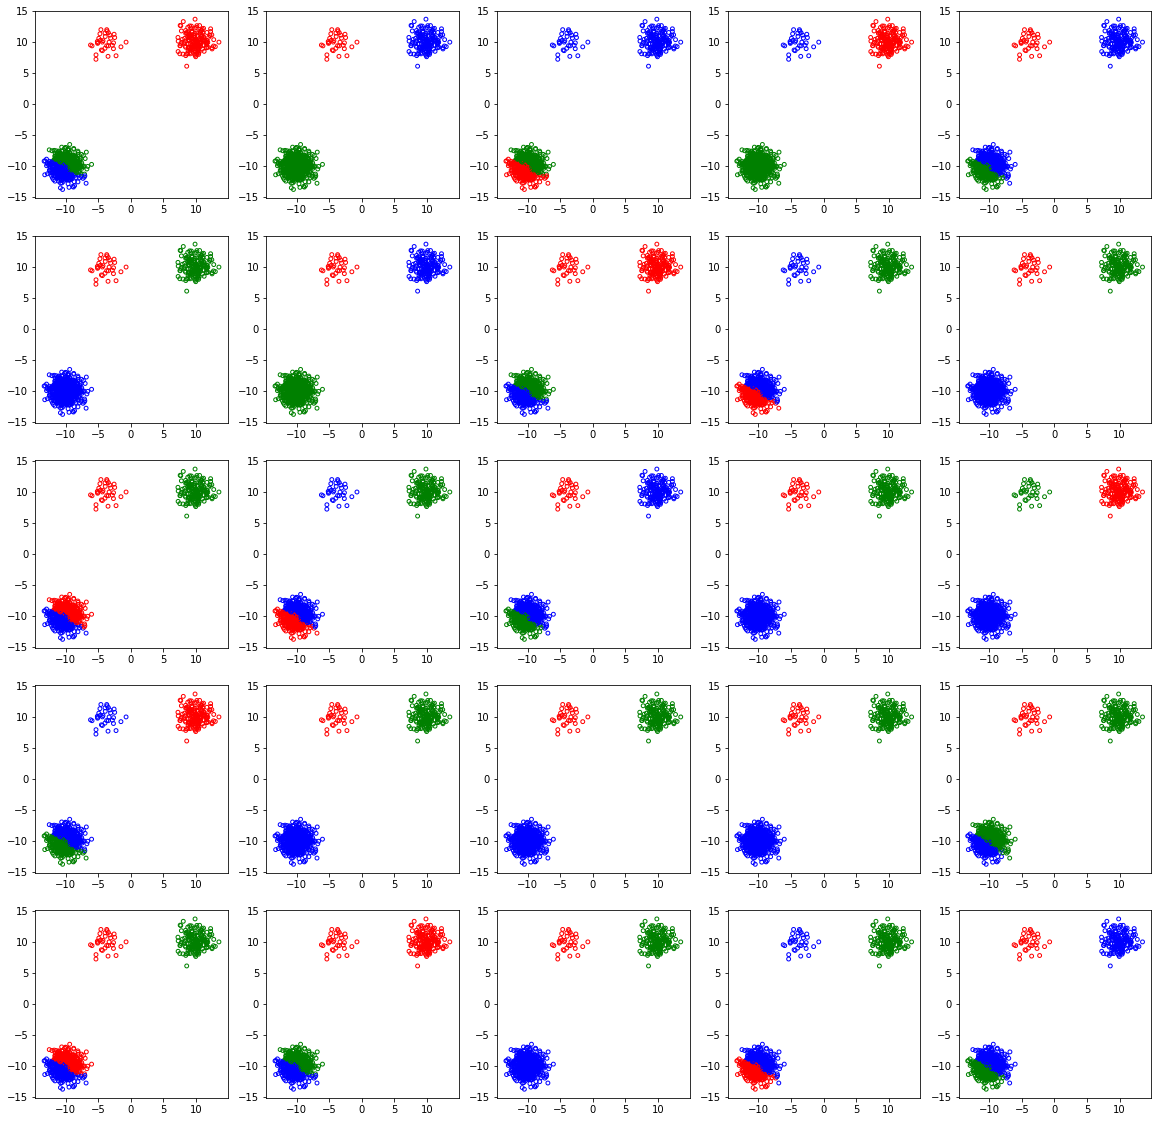

In [72]:
%matplotlib inline 
fig=plt.figure()
fig.set_size_inches(20, 20)
for f in np.arange(1,26,1):
#     print f
    

    spectral = cluster.SpectralClustering(n_clusters=3,
                                              eigen_solver='arpack',
                                              affinity="nearest_neighbors")

    spectral.fit(x)
    y_pred = spectral.labels_.astype(np.int)
    plt.subplot(5,5,f)
    plt.scatter(x[:, 0], x[:, 1], color=colors[y_pred], s=15, marker='o', facecolors='none')
